<img src="https://drive.google.com/uc?export=view&id=1XMSQvqGXdYM0McNCTafguLUn1uiL8zu_"  width="1500px" height="300px">

# <center> **Machine learning classifiers </center>**



In [23]:
#@title **1. Cargamos el dataset** { display-mode: "form" }
import os
#@markdown Ingresa el enlace del dataset. Por ejemplo:

path_ria = "https://drive.google.com/uc?export=download&id=1Qnl51MHl_3W6SfJxbuvEzv-1PDHDCJhm" #@param {type:"string"}


In [8]:
#@title **2. Importamos algunas libreriass que necesitamos**
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
#@title **3. cargamos nuestro dataset**
path_data = "ai4i2020.csv" #@param {type:"string"}
df = pd.read_csv(path_ria)
print(df.shape)
df.head()

(10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [11]:
#@title **4. Preparamos el dataset**
df = pd.read_csv(path_ria)
del df['UDI']
del df['Product ID']
del df['Type']
del df['TWF']
del df['PWF']
del df['HDF']
del df['OSF']
del df['RNF']


#@title **5. Hacemos una partición de los datos**
# Split into features and target
y_label =  "Machine failure"#@param {type:"string"}
size_test =  2000 #@param {type:"integer"}
X = df.drop(y_label, axis=1)
y = df[y_label]

print("X: ", X.shape, "y: ", y.shape)
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=size_test, stratify=y, random_state=42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)
df.head(10)

X:  (10000, 5) y:  (10000,)
(8000, 5) (2000, 5) (8000,) (2000,)


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,298.1,308.6,1551,42.8,0,0
1,298.2,308.7,1408,46.3,3,0
2,298.1,308.5,1498,49.4,5,0
3,298.2,308.6,1433,39.5,7,0
4,298.2,308.7,1408,40.0,9,0
5,298.1,308.6,1425,41.9,11,0
6,298.1,308.6,1558,42.4,14,0
7,298.1,308.6,1527,40.2,16,0
8,298.3,308.7,1667,28.6,18,0
9,298.5,309.0,1741,28.0,21,0


In [12]:
#@title **5. normalizamos los datos scale**
import numpy as np
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [13]:
#@title **6. Regresion Logistica**
from sklearn.linear_model import LogisticRegression

# Train a Logistic Regression model
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test_scaled)

# Report the results
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Accuracy Score:", accuracy_score(y_test, y_pred))

Confusion Matrix:
 [[1928    4]
 [  59    9]]
Accuracy Score: 0.9685


In [14]:
#@title **7. Decision Tree**
from sklearn.tree import DecisionTreeClassifier

# Train a Decision Tree model
number_depth =  2 #@param {type:"integer"}

model_dt = DecisionTreeClassifier(max_depth=number_depth, random_state=42)
model_dt.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred_dt = model_dt.predict(X_test_scaled)

# Report the results
print("Confusion Matrix (Decision Tree):\n", confusion_matrix(y_test, y_pred_dt))
print("Accuracy Score (Decision Tree):", accuracy_score(y_test, y_pred_dt))

Confusion Matrix (Decision Tree):
 [[1929    3]
 [  55   13]]
Accuracy Score (Decision Tree): 0.971


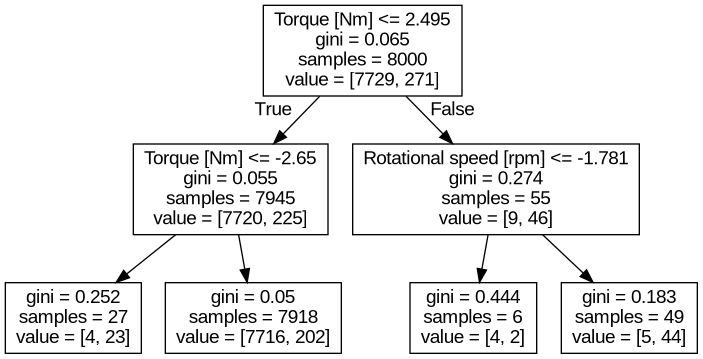

In [16]:
#@title **code** Podemos visualizar la salida
#!sudo apt-get install graphviz
from sklearn.tree import export_graphviz
from IPython.display import Image

df = pd.read_csv(path_ria)
del df['UDI']
del df['Product ID']
del df['Type']
del df['TWF']
del df['PWF']
del df['HDF']
del df['OSF']
del df['RNF']


export_graphviz(model_dt, out_file='tree_c.dot', feature_names=df.columns[:-1].values)
!dot -Tpng tree_c.dot > tree_c.png

Image(filename='tree_c.png')

Feature Importances (Decision Tree):
 Torque [Nm]                0.969428
Rotational speed [rpm]     0.030572
Air temperature [K]        0.000000
Process temperature [K]    0.000000
Tool wear [min]            0.000000
dtype: float64


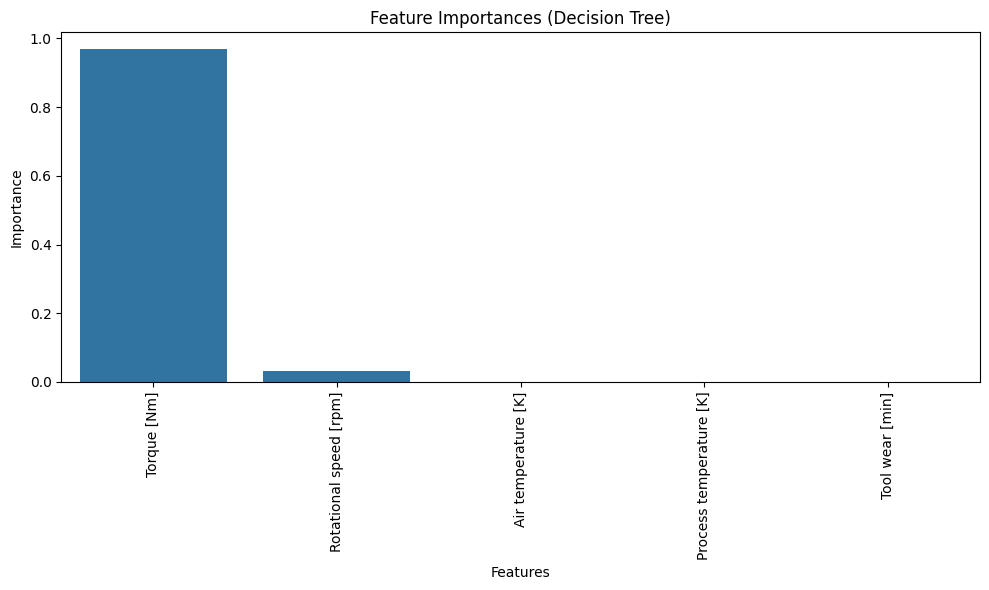

In [17]:
#@title **Feature Importance with Decision Tree**
# Get feature importances
feature_importances = model_dt.feature_importances_

# Create a pandas Series for easier handling and visualization
feature_importances_series = pd.Series(feature_importances, index=X_train.columns)

# Sort features by importance
sorted_feature_importances = feature_importances_series.sort_values(ascending=False)

# Print the sorted feature importances
print("Feature Importances (Decision Tree):\n", sorted_feature_importances)

# Visualize the feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x=sorted_feature_importances.index, y=sorted_feature_importances.values)
plt.xticks(rotation=90)
plt.title("Feature Importances (Decision Tree)")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

In [18]:
#@title **8. Random Forest**
from sklearn.ensemble import RandomForestClassifier

number_trees =  200 #@param {type:"integer"}

# Train a Random Forest model
model_rf = RandomForestClassifier(n_estimators=number_trees, random_state=42)
model_rf.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred_rf = model_rf.predict(X_test_scaled)

# Report the results
print("Confusion Matrix (Random Forest):\n", confusion_matrix(y_test, y_pred_rf))
print("Accuracy Score (Random Forest):", accuracy_score(y_test, y_pred_rf))

Confusion Matrix (Random Forest):
 [[1925    7]
 [  24   44]]
Accuracy Score (Random Forest): 0.9845


In [19]:
#@title **9. Support Vector Machine (SVM)**
from sklearn.svm import SVC

#@markdown Select the kernel type for the SVM:
kernel_type = "rbf" #@param ["linear", "poly", "rbf", "sigmoid"]

# Train an SVM model
model_svm = SVC(kernel=kernel_type, random_state=42)
model_svm.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred_svm = model_svm.predict(X_test_scaled)

# Report the results
print(f"Confusion Matrix (SVM with {kernel_type} kernel):\n", confusion_matrix(y_test, y_pred_svm))
print(f"Accuracy Score (SVM with {kernel_type} kernel):", accuracy_score(y_test, y_pred_svm))

Confusion Matrix (SVM with rbf kernel):
 [[1929    3]
 [  53   15]]
Accuracy Score (SVM with rbf kernel): 0.972


In [22]:
#@title **10. Make a prediction with a selected model**

#@markdown Select the model to use for prediction:
model_name = "Decision Tree" #@param ["Logistic Regression", "Decision Tree", "Random Forest", "SVM"]

#@markdown Enter the feature values:
air_temperature = 298.1 #@param {type:"number"}
process_temperature = 308.6 #@param {type:"number"}
rotational_speed = 1551 #@param {type:"number"}
torque = 42.8 #@param {type:"number"}
tool_wear = 0 #@param {type:"number"}

# Create a dictionary with the input values
input_data = {
    'Air temperature [K]': air_temperature,
    'Process temperature [K]': process_temperature,
    'Rotational speed [rpm]': rotational_speed,
    'Torque [Nm]': torque,
    'Tool wear [min]': tool_wear
}

# Convert the input data to a pandas DataFrame
input_df = pd.DataFrame([input_data])

# Scale the input data using the previously fitted scaler
input_scaled = scaler.transform(input_df)

# Select the model based on the user's choice
if model_name == "Logistic Regression":
    model = model
elif model_name == "Gaussian Naive Bayes":
    model = model_nb
elif model_name == "Decision Tree":
    model = model_dt
elif model_name == "Random Forest":
    model = model_rf
elif model_name == "SVM":
    model = model_svm
else:
    print("Invalid model selected.")

# Make a prediction
if 'model' in locals():
    prediction = model.predict(input_scaled)
    prediction_proba = model.predict_proba(input_scaled)

    # Display the prediction
    print(f"Prediction using {model_name}: {prediction[0]}")
    print(f"Prediction probabilities: {prediction_proba[0]}")

Prediction using Decision Tree: 0
Prediction probabilities: [0.97448851 0.02551149]



<img src="https://gitlab.com/bivl2ab/academico/cursos-uis/cv/cv-uis-student/raw/master/imgs/bannerThanks.jpg" style="width:1000px;">